**Bakery Sales Data - Data Cleaning, Date-Time Analysis, Exploratory Data Analysis, Revenue Analysis, Grouping, and Data Visualization**

Import the required libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data Analysis

In this section, I inspect the dataset to understand its structure,
identify missing values, check duplicate records and observe
the different values available in each column.

In [2]:
df = pd.read_csv("bakery_sales.csv")
print(df)

    OrderID   OrderDate          Product     Category  Quantity UnitPrice  \
0      1001  2026-10-01             Cake        Cakes       2.0       450   
1      1002  2026-10-02        cupcakes      Pastries       4.0       120   
2      1003  2026-10-03          Cookies      Cookies       6.0        80   
3      1004  not_a_date            Bread        Bread       3.0        60   
4      1005  2026-10-05         Brownies     Pastries       2.0       150   
5      1006  2026-10-06          Muffins     Pastries       NaN       100   
6      1007  2026-10-07       Croissants     Pastries       4.0       180   
7      1008  2026-10-08            Flour  Ingredients      10.0        40   
8      1009  2026-10-09    Baking Powder  Ingredients       8.0   unknown   
9      1010  2026-10-10  Chocolate Chips  Ingredients       5.0       120   
10     1005  2026-10-05         Brownies     Pastries       2.0       150   

          City  
0      Chennai  
1    bangalore  
2      Madurai  
3      

In [3]:
#first five records
df.head()

,OrderID,OrderDate,Product,Category,Quantity,UnitPrice,City
0,1001,2026-10-01,Cake,Cakes,2.0,450,Chennai
1,1002,2026-10-02,cupcakes,Pastries,4.0,120,bangalore
2,1003,2026-10-03,Cookies,Cookies,6.0,80,Madurai
3,1004,not_a_date,Bread,Bread,3.0,60,Chennai
4,1005,2026-10-05,Brownies,Pastries,2.0,150,Coimbatore


In [4]:
#last five records
df.tail()

,OrderID,OrderDate,Product,Category,Quantity,UnitPrice,City
6,1007,2026-10-07,Croissants,Pastries,4.0,180,chennai
7,1008,2026-10-08,Flour,Ingredients,10.0,40,Madurai
8,1009,2026-10-09,Baking Powder,Ingredients,8.0,unknown,Coimbatore
9,1010,2026-10-10,Chocolate Chips,Ingredients,5.0,120,Chennai
10,1005,2026-10-05,Brownies,Pastries,2.0,150,Coimbatore


In [5]:
#dataset structure
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   OrderID    11 non-null     int64  
 1   OrderDate  11 non-null     str    
 2   Product    11 non-null     str    
 3   Category   11 non-null     str    
 4   Quantity   10 non-null     float64
 5   UnitPrice  11 non-null     str    
 6   City       11 non-null     str    
dtypes: float64(1), int64(1), str(5)
memory usage: 748.0 bytes


In [6]:
#descriptive statistics
df.describe()

,OrderID,Quantity
count,11.000000,10.000000
mean,1005.454545,4.600000
std,2.876235,2.716207
min,1001.000000,2.000000
25%,1003.500000,2.250000
50%,1005.000000,4.000000
75%,1007.500000,5.750000
max,1010.000000,10.000000


In [7]:
#dataset dimensions
df.shape

(11, 7)

In [8]:
#missing values
df.isnull().sum()

OrderID      0
OrderDate    0
Product      0
Category     0
Quantity     1
UnitPrice    0
City         0
dtype: int64

In [9]:
#Check blank values
(df == "").sum()

OrderID      0
OrderDate    0
Product      0
Category     0
Quantity     0
UnitPrice    0
City         0
dtype: int64

In [10]:
#duplicate records
df.duplicated().sum()

np.int64(1)

In [13]:
#unique values
print("Products:", df["Product"].unique())
print("Categories:", df["Category"].unique())
print("Cities:", df["City"].unique())

Products: <StringArray>
[           'Cake',      ' cupcakes ',         'Cookies',           'Bread',
        'Brownies',         'Muffins',      'Croissants',           'Flour',
   'Baking Powder', 'Chocolate Chips']
Length: 10, dtype: str
Categories: <StringArray>
['Cakes', 'Pastries', 'Cookies', 'Bread', 'Ingredients']
Length: 5, dtype: str
Cities: <StringArray>
[   'Chennai',  'bangalore',    'Madurai', 'Coimbatore',  'Bangalore',
    'chennai',   ' Chennai']
Length: 7, dtype: str


In [14]:
print("Number of unique products:", df["Product"].nunique())
print("Number of unique categories:", df["Category"].nunique())
print("Number of unique cities:", df["City"].nunique())

Number of unique products: 10
Number of unique categories: 5
Number of unique cities: 7


# Data Cleaning

Data cleaning is performed to correct errors and improve the quality
of the dataset. It includes removing duplicates, correcting
inconsistent text, converting data types and handling missing values.

In [15]:
#duplicate records
df = df.drop_duplicates()

df.duplicated().sum()

np.int64(0)

In [16]:
#unwanted spaces and standardize text
df["Product"] = df["Product"].str.strip().str.title()

df["Category"] = df["Category"].str.strip().str.title()

df["City"] = df["City"].str.strip().str.title()

print("Products:", df["Product"].unique())
print("Categories:", df["Category"].unique())
print("Cities:", df["City"].unique())

Products: <StringArray>
[           'Cake',        'Cupcakes',         'Cookies',           'Bread',
        'Brownies',         'Muffins',      'Croissants',           'Flour',
   'Baking Powder', 'Chocolate Chips']
Length: 10, dtype: str
Categories: <StringArray>
['Cakes', 'Pastries', 'Cookies', 'Bread', 'Ingredients']
Length: 5, dtype: str
Cities: <StringArray>
['Chennai', 'Bangalore', 'Madurai', 'Coimbatore']
Length: 4, dtype: str


In [17]:
#order date into date format
df["OrderDate"] = pd.to_datetime(
    df["OrderDate"], errors="coerce"
)

df[["OrderID", "OrderDate"]]

,OrderID,OrderDate
0,1001,2026-10-01
1,1002,2026-10-02
2,1003,2026-10-03
3,1004,NaT
4,1005,2026-10-05
5,1006,2026-10-06
6,1007,2026-10-07
7,1008,2026-10-08
8,1009,2026-10-09
9,1010,2026-10-10


In [18]:
df["OrderDate"].isnull().sum()

np.int64(1)

In [19]:
#quantity and unit price into numeric format
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

df[["OrderID", "Quantity", "UnitPrice"]]

,OrderID,Quantity,UnitPrice
0,1001,2.0,450.0
1,1002,4.0,120.0
2,1003,6.0,80.0
3,1004,3.0,60.0
4,1005,2.0,150.0
5,1006,NaN,100.0
6,1007,4.0,180.0
7,1008,10.0,40.0
8,1009,8.0,NaN
9,1010,5.0,120.0


In [20]:
#missing values after conversion
df.isnull().sum()

OrderID      0
OrderDate    1
Product      0
Category     0
Quantity     1
UnitPrice    1
City         0
dtype: int64

In [21]:
df["Quantity"] = df["Quantity"].fillna(
    df["Quantity"].median()
)

df["UnitPrice"] = df["UnitPrice"].fillna(
    df["UnitPrice"].median()
)

In [22]:
df["OrderDate"] = df["OrderDate"].fillna(
    df["OrderDate"].dropna().sort_values().iloc[
        len(df["OrderDate"].dropna()) // 2
    ]
)

In [23]:
#Verify missing values
df.isnull().sum()

OrderID      0
OrderDate    0
Product      0
Category     0
Quantity     0
UnitPrice    0
City         0
dtype: int64

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   OrderID    10 non-null     int64         
 1   OrderDate  10 non-null     datetime64[us]
 2   Product    10 non-null     str           
 3   Category   10 non-null     str           
 4   Quantity   10 non-null     float64       
 5   UnitPrice  10 non-null     float64       
 6   City       10 non-null     str           
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 692.0 bytes


# New Column for Revenue

Revenue represents the total sales amount generated by each order.

Revenue is calculated by multiplying the quantity of products sold
by the unit price of each product.

In [25]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

df[["OrderID", "Product", "Quantity", "UnitPrice", "Revenue"]]

,OrderID,Product,Quantity,UnitPrice,Revenue
0,1001,Cake,2.0,450.0,900.0
1,1002,Cupcakes,4.0,120.0,480.0
2,1003,Cookies,6.0,80.0,480.0
3,1004,Bread,3.0,60.0,180.0
4,1005,Brownies,2.0,150.0,300.0
5,1006,Muffins,4.0,100.0,400.0
6,1007,Croissants,4.0,180.0,720.0
7,1008,Flour,10.0,40.0,400.0
8,1009,Baking Powder,8.0,120.0,960.0
9,1010,Chocolate Chips,5.0,120.0,600.0


In [26]:
df.head()

,OrderID,OrderDate,Product,Category,Quantity,UnitPrice,City,Revenue
0,1001,2026-10-01,Cake,Cakes,2.0,450.0,Chennai,900.0
1,1002,2026-10-02,Cupcakes,Pastries,4.0,120.0,Bangalore,480.0
2,1003,2026-10-03,Cookies,Cookies,6.0,80.0,Madurai,480.0
3,1004,2026-10-06,Bread,Bread,3.0,60.0,Chennai,180.0
4,1005,2026-10-05,Brownies,Pastries,2.0,150.0,Coimbatore,300.0


In [27]:
df.shape

(10, 8)

In [28]:
df["Revenue"].describe()

count     10.000000
mean     542.000000
std      252.885569
min      180.000000
25%      400.000000
50%      480.000000
75%      690.000000
max      960.000000
Name: Revenue, dtype: float64

In [29]:
#sales statistics
print("Mean Revenue:", df["Revenue"].mean())

print("Total Revenue:", df["Revenue"].sum())

print("Total Quantity Sold:", df["Quantity"].sum())

print("Highest Revenue:", df["Revenue"].max())

print("Lowest Revenue:", df["Revenue"].min())

Mean Revenue: 542.0
Total Revenue: 5420.0
Total Quantity Sold: 48.0
Highest Revenue: 960.0
Lowest Revenue: 180.0


In [30]:
#number of orders for each product
df["Product"].value_counts()

Product
Cake               1
Cupcakes           1
Cookies            1
Bread              1
Brownies           1
Muffins            1
Croissants         1
Flour              1
Baking Powder      1
Chocolate Chips    1
Name: count, dtype: int64

# Grouping and Aggregation

I will group the data by product, category and city to understand
which products and locations contribute more to bakery revenue.

In [31]:
#Revenue and quantity by product

product_summary = (
    df.groupby("Product")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        QuantitySold=("Quantity", "sum"),
        Orders=("OrderID", "count"),
        AverageRevenue=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

product_summary

,TotalRevenue,QuantitySold,Orders,AverageRevenue
Product,,,,
Baking Powder,960.0,8.0,1,960.0
Cake,900.0,2.0,1,900.0
Croissants,720.0,4.0,1,720.0
Chocolate Chips,600.0,5.0,1,600.0
Cupcakes,480.0,4.0,1,480.0
Cookies,480.0,6.0,1,480.0
Muffins,400.0,4.0,1,400.0
Flour,400.0,10.0,1,400.0
Brownies,300.0,2.0,1,300.0


In [32]:
#Revenue by category
category_summary = (
    df.groupby("Category")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        QuantitySold=("Quantity", "sum"),
        Orders=("OrderID", "count"),
        AverageRevenue=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

category_summary

,TotalRevenue,QuantitySold,Orders,AverageRevenue
Category,,,,
Ingredients,1960.0,23.0,3,653.333333
Pastries,1900.0,14.0,4,475.000000
Cakes,900.0,2.0,1,900.000000
Cookies,480.0,6.0,1,480.000000
Bread,180.0,3.0,1,180.000000


In [33]:
#Revenue by city
city_summary = (
    df.groupby("City")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        AverageRevenue=("Revenue", "mean"),
        Orders=("OrderID", "count"),
        QuantitySold=("Quantity", "sum")
    )
    .sort_values("TotalRevenue", ascending=False)
)

city_summary

,TotalRevenue,AverageRevenue,Orders,QuantitySold
City,,,,
Chennai,2400.0,600.0,4,14.0
Coimbatore,1260.0,630.0,2,10.0
Bangalore,880.0,440.0,2,8.0
Madurai,880.0,440.0,2,16.0


In [34]:
#Monthly sales summary
df["Month"] = df["OrderDate"].dt.to_period("M").astype(str)

monthly_summary = (
    df.groupby("Month")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        Orders=("OrderID", "count"),
        QuantitySold=("Quantity", "sum")
    )
    .sort_index()
)

monthly_summary

,TotalRevenue,Orders,QuantitySold
Month,,,
2026-10,5420.0,10,48.0


In [35]:
#Correlation between numeric columns
numeric_columns = [
    "Quantity", "UnitPrice", "Revenue"
]

correlation_table = df[numeric_columns].corr()

correlation_table

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.520788,0.150933
UnitPrice,-0.520788,1.000000,0.607246
Revenue,0.150933,0.607246,1.000000


In [36]:
#relationship between quantity and revenue
print(
    "Quantity-Revenue Correlation:",
    df["Quantity"].corr(df["Revenue"])
)

Quantity-Revenue Correlation: 0.1509328710138592


In [37]:
#city with the highest revenue
print("Highest Revenue City:")

print(city_summary.head(1))

Highest Revenue City:
         TotalRevenue  AverageRevenue  Orders  QuantitySold
City                                                       
Chennai        2400.0           600.0       4          14.0


In [38]:
#best-selling product by quantity
print("Best-Selling Product:")

print(
    product_summary.sort_values(
        "QuantitySold", ascending=False
    ).head(1)
)

Best-Selling Product:
         TotalRevenue  QuantitySold  Orders  AverageRevenue
Product                                                    
Flour           400.0          10.0       1           400.0


In [ ]:
#five revenue-generating orders
highest_revenue_orders = (
    df.sort_values("Revenue", ascending=False)
    [[
        "OrderID", "OrderDate", "Product",
        "Category", "Quantity", "UnitPrice",
        "City", "Revenue"
    ]]
    .head(5)
)

highest_revenue_orders

# Data Visualization

Data visualization helps us understand the sales information
through graphs and charts. It makes comparisons easier and helps
identify sales patterns.

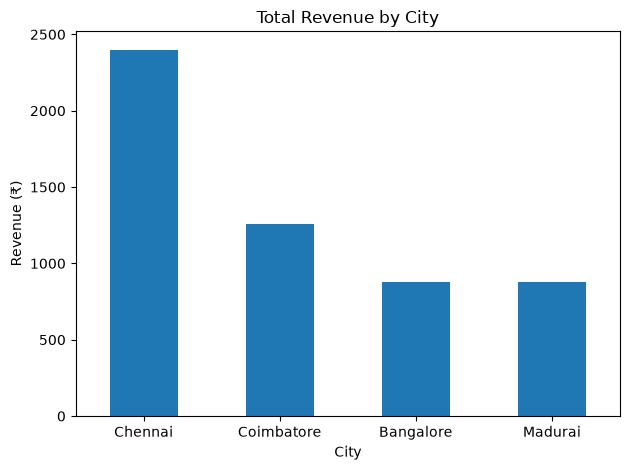

In [39]:
city_summary["TotalRevenue"].plot(
    kind="bar",
    title="Total Revenue by City"
)

plt.xlabel("City")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

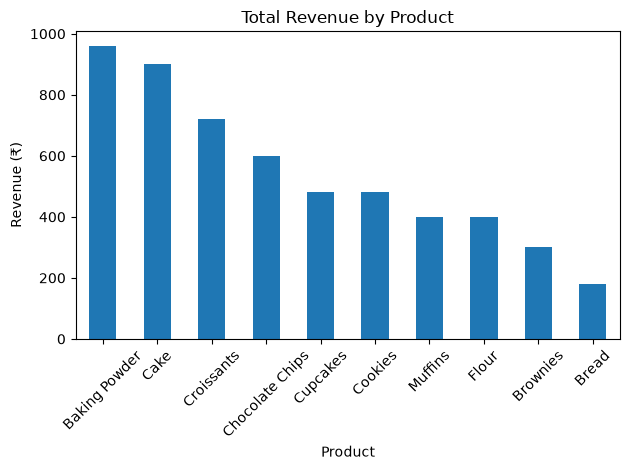

In [40]:
#Bar chart – Total revenue by product
product_summary["TotalRevenue"].plot(
    kind="bar",
    title="Total Revenue by Product"
)

plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

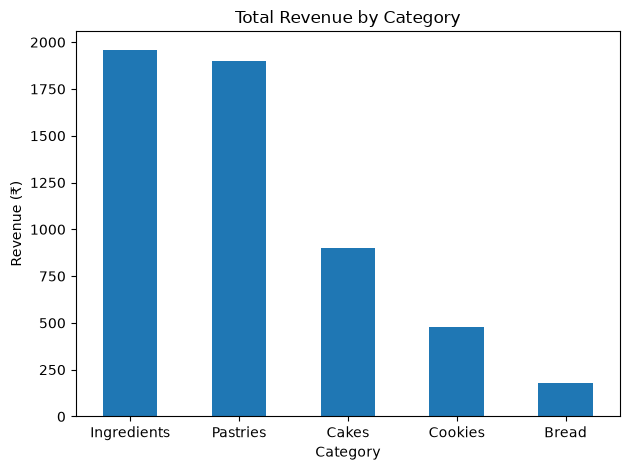

In [41]:
#Bar chart – Revenue by category
category_summary["TotalRevenue"].plot(
    kind="bar",
    title="Total Revenue by Category"
)

plt.xlabel("Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

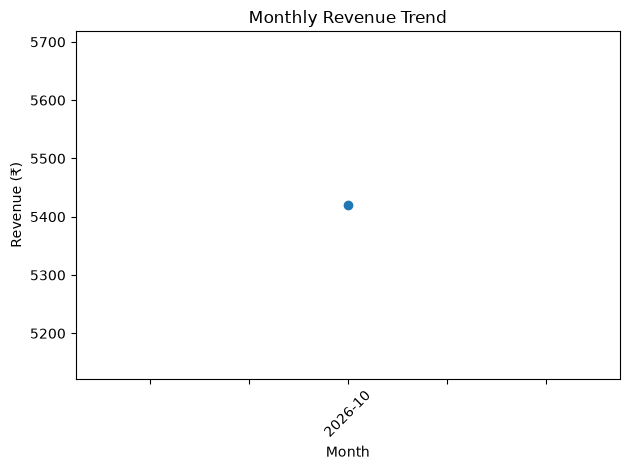

In [42]:
#Line chart – Monthly revenue trend
monthly_summary["TotalRevenue"].plot(
    kind="line",
    marker="o",
    title="Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

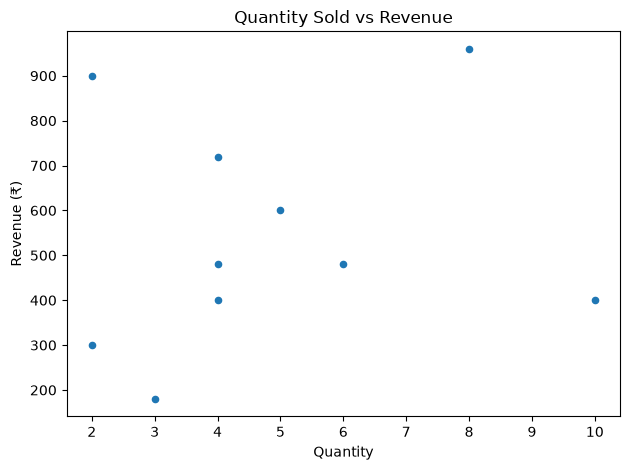

In [43]:
#Scatter plot – Quantity sold vs revenue
df.plot(
    kind="scatter",
    x="Quantity",
    y="Revenue",
    title="Quantity Sold vs Revenue"
)

plt.xlabel("Quantity")
plt.ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()

In [44]:
df

,OrderID,OrderDate,Product,Category,Quantity,UnitPrice,City,Revenue,Month
0,1001,2026-10-01,Cake,Cakes,2.0,450.0,Chennai,900.0,2026-10
1,1002,2026-10-02,Cupcakes,Pastries,4.0,120.0,Bangalore,480.0,2026-10
2,1003,2026-10-03,Cookies,Cookies,6.0,80.0,Madurai,480.0,2026-10
3,1004,2026-10-06,Bread,Bread,3.0,60.0,Chennai,180.0,2026-10
4,1005,2026-10-05,Brownies,Pastries,2.0,150.0,Coimbatore,300.0,2026-10
5,1006,2026-10-06,Muffins,Pastries,4.0,100.0,Bangalore,400.0,2026-10
6,1007,2026-10-07,Croissants,Pastries,4.0,180.0,Chennai,720.0,2026-10
7,1008,2026-10-08,Flour,Ingredients,10.0,40.0,Madurai,400.0,2026-10
8,1009,2026-10-09,Baking Powder,Ingredients,8.0,120.0,Coimbatore,960.0,2026-10
9,1010,2026-10-10,Chocolate Chips,Ingredients,5.0,120.0,Chennai,600.0,2026-10


In [45]:
df["Month"] = df["OrderDate"].dt.to_period("M")

print(df[["OrderDate", "Month"]])

   OrderDate    Month
0 2026-10-01  2026-10
1 2026-10-02  2026-10
2 2026-10-03  2026-10
3 2026-10-06  2026-10
4 2026-10-05  2026-10
5 2026-10-06  2026-10
6 2026-10-07  2026-10
7 2026-10-08  2026-10
8 2026-10-09  2026-10
9 2026-10-10  2026-10


In [46]:
monthly_revenue = df.groupby("Month")["Revenue"].sum()

print(monthly_revenue)

Month
2026-10    5420.0
Freq: M, Name: Revenue, dtype: float64
